In [49]:
#choose python environment if doesn't work use this ->>   
# .\.venv\Scripts\Activate.ps1

In [50]:
#installs all libraries to environment
%pip install pandas numpy matplotlib seaborn scikit-learn kagglehub

Note: you may need to restart the kernel to use updated packages.


In [51]:
#import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
from kagglehub import KaggleDatasetAdapter
from pathlib import Path


In [68]:
#Creating folders FOR CLEAN CSV FILES
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

In [53]:
#READ CSV FILE AS A TABLE IT WILL ONLY SHOW THE FIRST 5 ROW BECAUSE OF DF.HEAD() FUNCTION, DF IS HOW WE DEFINE THE TABLE.
#MAKE SURE FILE IS IN DATA FOLDER!!!
df = pd.read_csv(
    DATA_DIR / "bim_ai_civil_engineering_dataset.csv"
)
df.head()


,Project_ID,Project_Type,Location,Start_Date,End_Date,Planned_Cost,Actual_Cost,Cost_Overrun,Planned_Duration,Actual_Duration,...,Energy_Consumption,Material_Usage,Labor_Hours,Equipment_Utilization,Accident_Count,Safety_Risk_Score,Image_Analysis_Score,Anomaly_Detected,Completion_Percentage,Risk_Level
0,PJT_1,Tunnel,Houston,2020-01-01,2021-09-26,12260784,1.505450e+07,2.793720e+06,699,813.914852,...,25202.994687,244.843310,6602,76.300184,8,6.192198,52.988330,0,95.006343,High
1,PJT_2,Dam,Houston,2020-01-02,2020-12-06,2369277,3.507054e+06,1.137777e+06,269,384.118221,...,49066.172542,263.123025,7121,63.527671,5,2.134473,50.885745,0,25.294824,Low
2,PJT_3,Building,Houston,2020-01-03,2021-12-05,23299783,2.169213e+07,-1.607656e+06,899,1081.777915,...,48192.547163,608.985023,9956,47.099444,2,3.113728,93.905836,0,97.478830,Medium
3,PJT_4,Dam,Houston,2020-01-04,2022-04-12,24499306,2.946966e+07,4.970354e+06,809,974.565655,...,19811.151750,673.574344,3725,86.846394,5,4.070101,90.454316,1,95.098131,High
4,PJT_5,Dam,Seattle,2020-01-05,2022-02-12,1749971,2.329338e+06,5.793670e+05,354,347.990127,...,44866.565169,765.476122,4368,61.827163,6,2.759351,78.391069,0,43.624985,Low


In [54]:
# TO UNDERSTAND INFO AND DATA TYPES OF EACH COLUMN IN THE TABLE
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Project_ID             1000 non-null   str    
 1   Project_Type           1000 non-null   str    
 2   Location               1000 non-null   str    
 3   Start_Date             1000 non-null   str    
 4   End_Date               1000 non-null   str    
 5   Planned_Cost           1000 non-null   int64  
 6   Actual_Cost            1000 non-null   float64
 7   Cost_Overrun           1000 non-null   float64
 8   Planned_Duration       1000 non-null   int64  
 9   Actual_Duration        1000 non-null   float64
 10  Schedule_Deviation     1000 non-null   float64
 11  Vibration_Level        1000 non-null   float64
 12  Crack_Width            1000 non-null   float64
 13  Load_Bearing_Capacity  1000 non-null   float64
 14  Temperature            1000 non-null   float64
 15  Humidity        

In [55]:
#include="all" includes numeric and text columns.
# .T turns the table sideways to make it easier to read.
# count counts available values.
#mean, min, and max describe numeric values.
#unique, top, and freq describe text categories.
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Project_ID,1000,1000,PJT_1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Project_Type,1000,5,Bridge,210,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,1000,5,Los Angeles,211,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Start_Date,1000,1000,2020-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
End_Date,1000,691,2022-12-08,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Planned_Cost,1000.0,NaN,NaN,NaN,26415087.626,14485761.884914,1045475.0,14310133.0,26908602.0,39570293.25,49968538.0
Actual_Cost,1000.0,NaN,NaN,NaN,31541079.260366,18095958.811092,1180251.527639,16096546.659396,31339224.455522,45327468.954879,72519386.550836
Cost_Overrun,1000.0,NaN,NaN,NaN,5125991.634366,5931350.171601,-4648578.917822,581066.139366,3326817.482013,8665132.386436,24012292.061622
Planned_Duration,1000.0,NaN,NaN,NaN,538.62,204.531765,180.0,361.0,535.5,713.0,899.0
Actual_Duration,1000.0,NaN,NaN,NaN,645.560751,269.383932,165.278211,424.252757,635.469136,831.64495,1340.352531


In [56]:
#make a clean copy of the original table
df_clean = df.copy()

In [57]:
#Give new names to columns
new_names = {
    "Project_ID": "project_id",
    "Project_Type": "project_type",
    "Location": "location",
    "Start_Date": "start_date",
    "End_Date": "end_date",
    "Planned_Cost": "planned_cost",
    "Actual_Cost": "actual_cost",
    "Cost_Overrun": "cost_overrun",
    "Planned_Duration": "planned_duration", 
    "Actual_Duration": "actual_duration",
    "Schedule_Deviation": "schedule_deviation",
    "Vibration_Level": "vibration_level",
    "Crack_Width": "crack_width",
    "Load_Bearing_Capacity": "load_bearing_capacity",
    "Temperature": "temperature",
    "Humidity": "humidity",
    "Weather_Conditions": "weather_conditions",
    "Air_Quality_Index": "air_quality_index",
    "Energy_Consumption": "energy_consumption",
    "Material_Usage": "material_usage",
    "Accident_Count": "accident_count",
    "Safety_Risk_Score": "safety_risk_score",
    "Image_Analysis_Score": "image_analysis_score",
    "Anomaly_Detected": "anomaly_detected",
    "Completion_Percentage": "completion_percentage",
    "Risk_Level": "risk_level",

}
df_clean = df_clean.rename(columns=new_names)
df_clean.columns.tolist()

['project_id',
 'project_type',
 'location',
 'start_date',
 'end_date',
 'planned_cost',
 'actual_cost',
 'cost_overrun',
 'planned_duration',
 'actual_duration',
 'schedule_deviation',
 'vibration_level',
 'crack_width',
 'load_bearing_capacity',
 'temperature',
 'humidity',
 'Weather_Condition',
 'air_quality_index',
 'energy_consumption',
 'material_usage',
 'Labor_Hours',
 'Equipment_Utilization',
 'accident_count',
 'safety_risk_score',
 'image_analysis_score',
 'anomaly_detected',
 'completion_percentage',
 'risk_level']

In [58]:
#Check for duplicates rows in the table
n_duplicates = df_clean.duplicated().sum()
print(f"Number of duplicate rows: {n_duplicates}")


Number of duplicate rows: 0


In [59]:
#check for missing data in the table(n=missing) and percentage of missing data in the table(pct_missing)
def missing_report(data):
    n_missing = data.isnull().sum()
    pct_missing = (n_missing / len(data)) * 100
    report = pd.DataFrame({
        "n_nissing": n_missing,
        "pct_missing": pct_missing  
    })
    return report.sort_values(
        "pct_missing", 
        ascending=False
    )
missing = missing_report(df_clean)
missing

,n_nissing,pct_missing
project_id,0,0.0
project_type,0,0.0
location,0,0.0
start_date,0,0.0
end_date,0,0.0
planned_cost,0,0.0
actual_cost,0,0.0
cost_overrun,0,0.0
planned_duration,0,0.0
actual_duration,0,0.0


In [60]:
#column removal based on lack of interest 
columns_to_drop = [
    'project_id',
    'location',
    'start_date',
    'end_date',
    'planned_cost',
    'actual_cost',
    'planned_duration',
    'actual_duration',
    'vibration_level',
    'crack_width',
    'load_bearing_capacity',
    'temperature',
    'humidity',
    'Weather_Condition',
    'air_quality_index',
    'Labor_Hours',
    'Equipment_Utilization',
    'accident_count',
    'safety_risk_score',
    'image_analysis_score',
    'anomaly_detected',
    'completion_percentage',
    'risk_level']

df_clean = df_clean.drop(columns=columns_to_drop)

print(
    f"Remaining columns ({df_clean.shape[1]}): "
    f"{df_clean.columns.tolist()}"
)

Remaining columns (5): ['project_type', 'cost_overrun', 'schedule_deviation', 'energy_consumption', 'material_usage']


In [61]:
#clean out row's with unwanted project types

df_clean = df_clean[
    df_clean["project_type"] == "Building"
].copy()

df_clean = df_clean.reset_index(drop=True)

print(f"Building info: {len(df_clean)}")

df_clean.head()

Building info: 190


,project_type,cost_overrun,schedule_deviation,energy_consumption,material_usage
0,Building,-1.607656e+06,182.777915,48192.547163,608.985023
1,Building,3.558336e+05,39.587118,14480.617880,963.106378
2,Building,1.625532e+07,-47.136473,33093.068035,674.865331
3,Building,5.912716e+06,172.477007,8270.704202,862.342227
4,Building,1.153068e+07,46.454548,8186.661562,979.464616


In [62]:
#check the info and data types of each column in the cleaned table
df_clean.info()
df_clean.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 190 entries, 0 to 189
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   project_type        190 non-null    str    
 1   cost_overrun        190 non-null    float64
 2   schedule_deviation  190 non-null    float64
 3   energy_consumption  190 non-null    float64
 4   material_usage      190 non-null    float64
dtypes: float64(4), str(1)
memory usage: 7.6 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
project_type,190,1,Building,190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cost_overrun,190.0,NaN,NaN,NaN,5333935.259732,6009665.81414,-4648578.917822,328724.019303,3892780.82211,9357844.556398,21964087.096786
schedule_deviation,190.0,NaN,NaN,NaN,118.285946,113.640351,-79.136491,36.236407,97.760068,196.019903,418.262914
energy_consumption,190.0,NaN,NaN,NaN,26851.955836,12962.455573,5054.162626,15532.56031,26747.681746,38730.337461,49918.904568
material_usage,190.0,NaN,NaN,NaN,542.619107,263.366156,108.627076,314.302332,509.219369,781.677858,997.926597


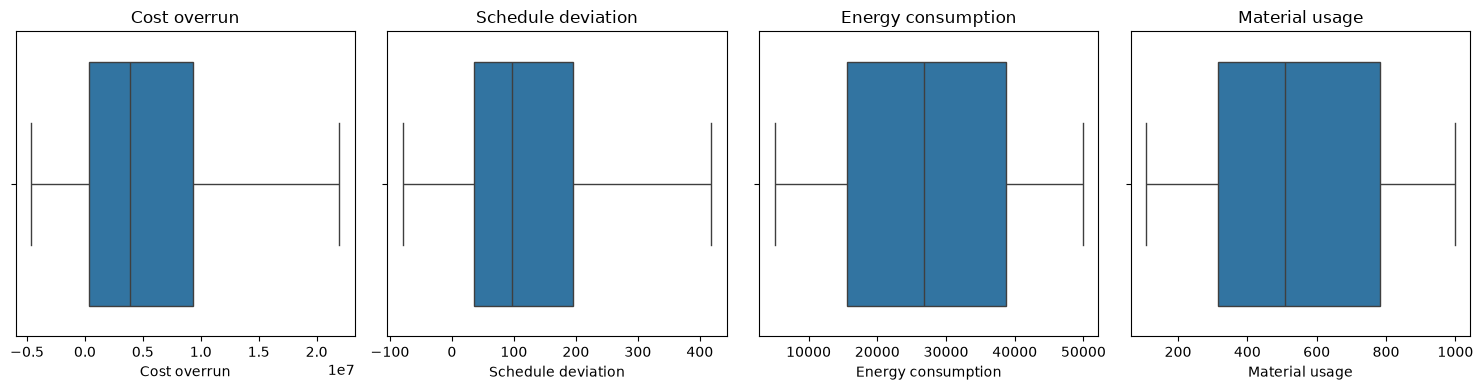

In [65]:
#inspect the distribution of the remaining numeric columns using boxplots to identify outliers and understand the spread of the data.

#Box ->	Middle 50% of values
#Line inside the box ->	Median—the middle value
#Whiskers->Range defined by the boxplot rule
#Dots beyond the whiskers ->Potential outliers to investigate

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

sns.boxplot(x=df_clean["cost_overrun"], ax=axes[0])
axes[0].set_title("Cost overrun")
axes[0].set_xlabel("Cost overrun")

sns.boxplot(x=df_clean["schedule_deviation"], ax=axes[1])
axes[1].set_title("Schedule deviation")
axes[1].set_xlabel("Schedule deviation")

sns.boxplot(x=df_clean["energy_consumption"], ax=axes[2])
axes[2].set_title("Energy consumption")
axes[2].set_xlabel("Energy consumption")

sns.boxplot(x=df_clean["material_usage"], ax=axes[3])
axes[3].set_title("Material usage")
axes[3].set_xlabel("Material usage")

plt.tight_layout()

plt.show()


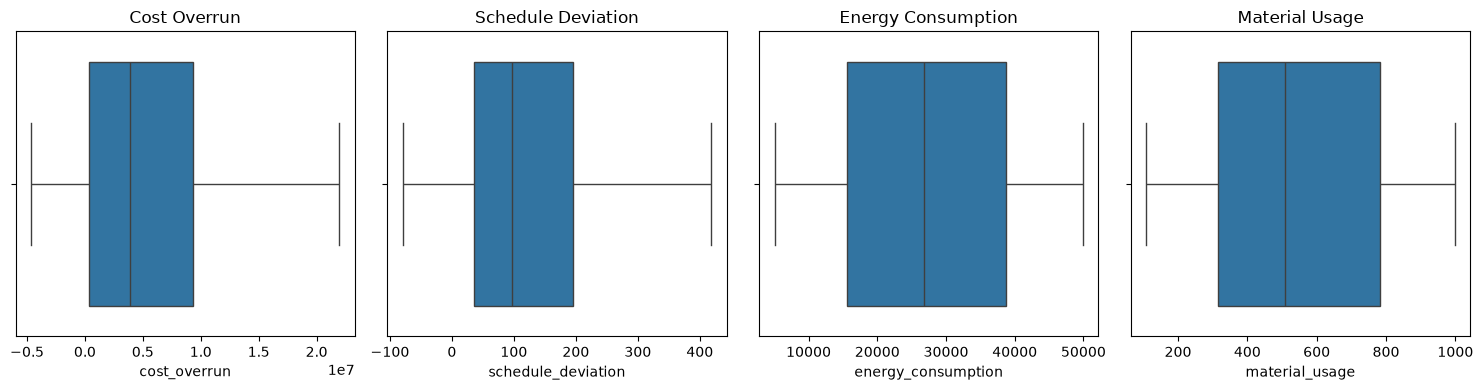

In [73]:
#to export file to figure folder
fig, axes = plt.subplots(1, 4,figsize=(15, 4))
sns.boxplot(x=df_clean["cost_overrun"], ax=axes[0])
axes[0].set_title("Cost Overrun")

sns.boxplot(x=df_clean["schedule_deviation"], ax=axes[1])
axes[1].set_title("Schedule Deviation")

sns.boxplot(x=df_clean["energy_consumption"], ax=axes[2])
axes[2].set_title("Energy Consumption")

sns.boxplot(x=df_clean["material_usage"], ax=axes[3])
axes[3].set_title("Material Usage")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_building_boxplots.png")
plt.show()

In [76]:
#percentile = extreme counts, 
#IQR = interquartile range, Q1 = 25th percentile, Q3 = 75th percentile
cost = df_clean["cost_overrun"]
q1, q3 = cost.quantile([0.25, 0.75])
iqr = q3 - q1

iqr_outliers = (
    (cost < (q1 - 1.5 * iqr))   
    | (cost > (q3 + 1.5 * iqr))
)                 #IQR rule for outliers
#percentile = extreme counts
p01,p99 = cost.quantile([0.01, 0.99])   #1st and 99th percentile
pct_outliers = (cost < p01) | (cost > p99) 
print(f"IQR rule: {iqr_outliers.sum()} flagged records")
print(f"Percentile rule: {pct_outliers.sum()} flagged records")

IQR rule: 0 flagged records
Percentile rule: 4 flagged records


In [77]:
#innspecting 4 extreme building cases
df_clean[pct_outliers]

,project_type,cost_overrun,schedule_deviation,energy_consumption,material_usage
41,Building,2.196409e+07,153.919305,8387.250845,484.211879
63,Building,2.093623e+07,239.120598,20804.883380,267.902121
119,Building,-3.558293e+06,130.269435,38546.016719,507.822698
144,Building,-4.648579e+06,193.250858,15668.477940,456.346986


In [81]:
final_columns = [
    "project_type",
    "cost_overrun",
    "schedule_deviation",
    "energy_consumption",
    "material_usage"
]
df_clean = df_clean[final_columns]
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 190 entries, 0 to 189
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   project_type        190 non-null    str    
 1   cost_overrun        190 non-null    float64
 2   schedule_deviation  190 non-null    float64
 3   energy_consumption  190 non-null    float64
 4   material_usage      190 non-null    float64
dtypes: float64(4), str(1)
memory usage: 7.6 KB


In [83]:
#comparing both tables to see if the cleaning process was successful
comparison = pd.DataFrame(
    {
        "raw":[
            len(df),
            df.shape[1],
            df.select_dtypes("number").shape[1],
            df.isna().mean().mean()*100,
            df.memory_usage(deep=True).sum() / 1e6
        ],
        "clean":[
            len(df_clean),
            df_clean.shape[1],
            df_clean.select_dtypes("number").shape[1],
            df.isna().mean().mean()*100,
            df_clean.memory_usage(deep=True).sum() / 1e6
        ]
    },
    index=[
        "rows",
        "columns",
        "numeric columns",
        "missing values (%)",
        "memory usage (MB)"
    ],
)
comparison

,raw,clean
rows,1000.000000,190.000000
columns,28.000000,5.000000
numeric columns,21.000000,4.000000
missing values (%),0.000000,0.000000
memory usage (MB),0.561385,0.017042


In [84]:
#savee cleaned table to csv file in data folder
clean_path = DATA_DIR / ("BUILDING_DATA.CSV")
df_clean.to_csv(clean_path, index=False)

print(
    f"Cleaned table saved to: {clean_path}"
    f"({clean_path.stat().st_size / 1e6:.2f} MB)"
      )

Cleaned table saved to: data\BUILDING_DATA.CSV(0.02 MB)
